In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/kamkadir17/medical_noshow/master/KaggleV2-May-2016.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [2]:
df = df.rename(columns={"No-show": "NoShow"})
df["NoShow"] = (df["NoShow"] == "Yes").astype(int)

df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"])
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"])
df["LeadTime"] = (df["AppointmentDay"].dt.normalize() - df["ScheduledDay"].dt.normalize()).dt.days

df = df[df["Age"] >= 0]
df = df[df["LeadTime"] >= 0]

print(df.shape)
print("No-show rate:", round(df["NoShow"].mean(), 3))

(110521, 15)
No-show rate: 0.202


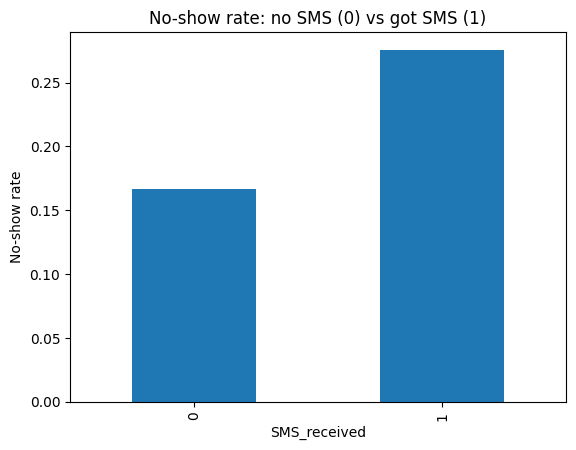

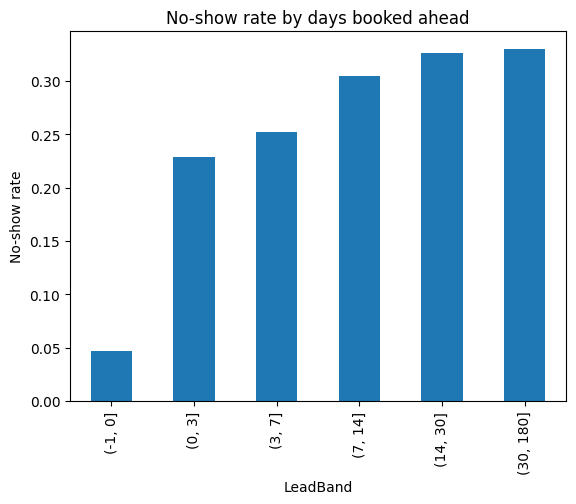

In [3]:
import matplotlib.pyplot as plt

df.groupby("SMS_received")["NoShow"].mean().plot(kind="bar")
plt.title("No-show rate: no SMS (0) vs got SMS (1)")
plt.ylabel("No-show rate")
plt.show()

df["LeadBand"] = pd.cut(df["LeadTime"], bins=[-1, 0, 3, 7, 14, 30, 180])
df.groupby("LeadBand", observed=True)["NoShow"].mean().plot(kind="bar")
plt.title("No-show rate by days booked ahead")
plt.ylabel("No-show rate")
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score

features = ["Age", "LeadTime", "SMS_received", "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Handcap"]
X = df[features]
y = df["NoShow"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

baseline_pred = (X_test["LeadTime"] > 14).astype(int)

print("Baseline precision:", round(precision_score(y_test, baseline_pred), 3))
print("Baseline recall:", round(recall_score(y_test, baseline_pred), 3))
print("Baseline F1:", round(f1_score(y_test, baseline_pred), 3))

Baseline precision: 0.331
Baseline recall: 0.416
Baseline F1: 0.369


In [5]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

print("LogReg precision:", round(precision_score(y_test, lr_pred), 3))
print("LogReg recall:", round(recall_score(y_test, lr_pred), 3))
print("LogReg F1:", round(f1_score(y_test, lr_pred), 3))

LogReg precision: 0.313
LogReg recall: 0.554
LogReg F1: 0.4


In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb = HistGradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

print("GB precision:", round(precision_score(y_test, gb_pred), 3))
print("GB recall:", round(recall_score(y_test, gb_pred), 3))
print("GB F1:", round(f1_score(y_test, gb_pred), 3))

GB precision: 0.592
GB recall: 0.009
GB F1: 0.019


In [7]:
gb_prob = gb.predict_proba(X_test)[:, 1]

for t in [0.3, 0.2, 0.1]:
    pred = (gb_prob >= t).astype(int)
    print("Threshold", t, "- precision:", round(precision_score(y_test, pred), 3), "recall:", round(recall_score(y_test, pred), 3), "F1:", round(f1_score(y_test, pred), 3))

Threshold 0.3 - precision: 0.352 recall: 0.48 F1: 0.406
Threshold 0.2 - precision: 0.304 recall: 0.833 F1: 0.445
Threshold 0.1 - precision: 0.28 recall: 0.933 F1: 0.43


In [8]:

pred = (gb_prob >= 0.2).astype(int)

showed_up = (y_test == 0)
flagged = (pred == 1)

print("People who actually showed up:", showed_up.sum())
print("...but got flagged as risky anyway:", (showed_up & flagged).sum())
print("Share of attenders wrongly flagged:", round((showed_up & flagged).sum() / showed_up.sum(), 3))
print()
print("Actual no-shows:", (y_test == 1).sum())
print("...that we caught:", ((y_test == 1) & flagged).sum())

People who actually showed up: 17642
...but got flagged as risky anyway: 8523
Share of attenders wrongly flagged: 0.483

Actual no-shows: 4463
...that we caught: 3719


In [9]:
call_list = pd.DataFrame({"risk": gb_prob, "actual": y_test.values}).sort_values("risk", ascending=False)

top_n = int(len(call_list) * 0.10)
top = call_list.head(top_n)

print("Clinic calls the top", top_n, "riskiest patients out of", len(call_list))
print("No-shows caught in that call list:", int(top["actual"].sum()), "of", int(call_list["actual"].sum()))
print("So they catch", round(top["actual"].sum() / call_list["actual"].sum() * 100, 1), "% of all no-shows by calling only 10% of patients")
print("And", round(top["actual"].mean() * 100, 1), "% of the people they call really would have no-showed")

Clinic calls the top 2210 riskiest patients out of 22105
No-shows caught in that call list: 888 of 4463
So they catch 19.9 % of all no-shows by calling only 10% of patients
And 40.2 % of the people they call really would have no-showed


In [10]:
df = df.sort_values("AppointmentDay").reset_index(drop=True)
df["PriorApps"] = df.groupby("PatientId").cumcount()
df["PriorNoShows"] = df.groupby("PatientId")["NoShow"].cumsum() - df["NoShow"]
df["PriorNoShowRate"] = (df["PriorNoShows"] / df["PriorApps"]).fillna(0)

features = ["Age", "LeadTime", "SMS_received", "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Handcap", "PriorNoShowRate", "PriorApps"]
X = df[features]
y = df["NoShow"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

gb = HistGradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
gb_prob = gb.predict_proba(X_test)[:, 1]

call_list = pd.DataFrame({"risk": gb_prob, "actual": y_test.values}).sort_values("risk", ascending=False)
top_n = int(len(call_list) * 0.10)
top = call_list.head(top_n)

print("Catch", round(top["actual"].sum() / call_list["actual"].sum() * 100, 1), "% of all no-shows calling only 10%")
print(round(top["actual"].mean() * 100, 1), "% of the call list really will no-show")

Catch 22.3 % of all no-shows calling only 10%
45.1 % of the call list really will no-show


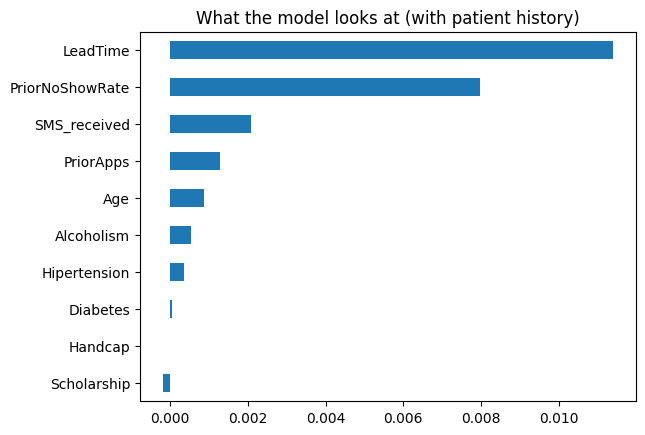

In [11]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(gb, X_test, y_test, n_repeats=5, random_state=42)
pd.Series(imp.importances_mean, index=features).sort_values().plot(kind="barh")
plt.title("What the model looks at (with patient history)")
plt.show()

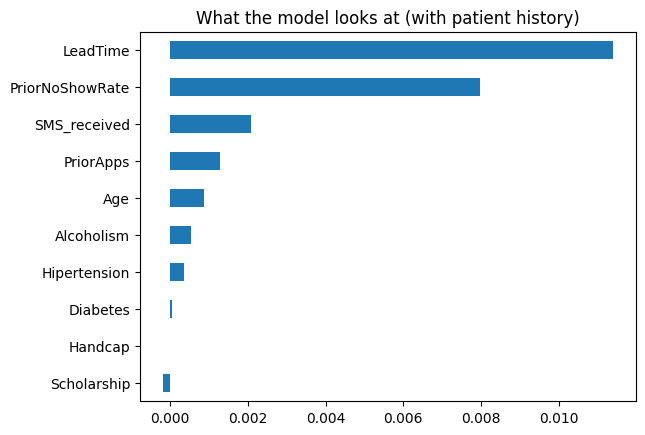

In [12]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(gb, X_test, y_test, n_repeats=5, random_state=42)
pd.Series(imp.importances_mean, index=features).sort_values().plot(kind="barh")
plt.title("What the model looks at (with patient history)")
plt.show()

In [13]:
df["AppWeekday"] = df["AppointmentDay"].dt.weekday
df["SchedHour"] = df["ScheduledDay"].dt.hour

features = ["Age", "LeadTime", "SMS_received", "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Handcap", "PriorNoShowRate", "PriorApps", "AppWeekday", "SchedHour"]
X = df[features]
y = df["NoShow"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

gb = HistGradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
gb_prob = gb.predict_proba(X_test)[:, 1]

call_list = pd.DataFrame({"risk": gb_prob, "actual": y_test.values}).sort_values("risk", ascending=False)
top_n = int(len(call_list) * 0.10)
top = call_list.head(top_n)

print("Catch", round(top["actual"].sum() / call_list["actual"].sum() * 100, 1), "% of all no-shows calling only 10%")
print(round(top["actual"].mean() * 100, 1), "% of the call list really will no-show")

Catch 22.7 % of all no-shows calling only 10%
45.8 % of the call list really will no-show


In [14]:
time_train = df[df["AppointmentDay"] < "2016-05-20"]
time_test = df[df["AppointmentDay"] >= "2016-05-20"]

gb_time = HistGradientBoostingClassifier(random_state=42)
gb_time.fit(time_train[features], time_train["NoShow"])
prob_time = gb_time.predict_proba(time_test[features])[:, 1]

cl = pd.DataFrame({"risk": prob_time, "actual": time_test["NoShow"].values}).sort_values("risk", ascending=False)
top_t = cl.head(int(len(cl) * 0.10))

print("Trained on", len(time_train), "earlier appointments, tested on", len(time_test), "later ones")
print("Catch", round(top_t["actual"].sum() / cl["actual"].sum() * 100, 1), "% of no-shows calling only 10%")
print(round(top_t["actual"].mean() * 100, 1), "% of the call list really will no-show")

Trained on 63532 earlier appointments, tested on 46989 later ones
Catch 21.2 % of no-shows calling only 10%
40.7 % of the call list really will no-show


In [15]:

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

gb_v = HistGradientBoostingClassifier(random_state=42)
gb_v.fit(X_tr, y_tr)
val_prob = gb_v.predict_proba(X_val)[:, 1]

ts = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]
best_t = max(ts, key=lambda t: f1_score(y_val, (val_prob >= t).astype(int)))

test_prob = gb_v.predict_proba(X_test)[:, 1]
final_pred = (test_prob >= best_t).astype(int)

print("Best alarm level chosen on validation:", best_t)
print("TEST precision:", round(precision_score(y_test, final_pred), 3))
print("TEST recall:", round(recall_score(y_test, final_pred), 3))
print("TEST F1:", round(f1_score(y_test, final_pred), 3))

Best alarm level chosen on validation: 0.25
TEST precision: 0.343
TEST recall: 0.662
TEST F1: 0.452


In [16]:
from sklearn.metrics import accuracy_score, roc_auc_score

print("=== FINAL TEST RESULTS (held-out 20% test split, alarm level 0.25 chosen on validation) ===")
print("Test accuracy:", round(accuracy_score(y_test, final_pred), 3))
print("Test ROC AUC:", round(roc_auc_score(y_test, test_prob), 3))


=== FINAL TEST RESULTS (held-out 20% test split, alarm level 0.25 chosen on validation) ===
Test accuracy: 0.676
Test ROC AUC: 0.745


In [17]:
cl_rule = pd.DataFrame({"risk": X_test["LeadTime"].values, "actual": y_test.values}).sort_values("risk", ascending=False, kind="stable")
cl_model = pd.DataFrame({"risk": test_prob, "actual": y_test.values}).sort_values("risk", ascending=False, kind="stable")

top_n = int(len(cl_model) * 0.10)
top_rule = cl_rule.head(top_n)
top_model = cl_model.head(top_n)

print("Both get to call the top 10%:", top_n, "patients")
print()
print("Simple rule: catches", round(top_rule["actual"].sum() / cl_rule["actual"].sum() * 100, 1), "% of no-shows,", round(top_rule["actual"].mean() * 100, 1), "% of its calls are real")
print("Our model: catches", round(top_model["actual"].sum() / cl_model["actual"].sum() * 100, 1), "% of no-shows,", round(top_model["actual"].mean() * 100, 1), "% of its calls are real")

Both get to call the top 10%: 2210 patients

Simple rule: catches 16.6 % of no-shows, 33.6 % of its calls are real
Our model: catches 22.9 % of no-shows, 46.2 % of its calls are real


In [18]:
print("Rule calls that hit a real no-show:", int(top_rule["actual"].sum()))
print("Model calls that hit a real no-show:", int(top_model["actual"].sum()))
print("Extra caught by the model:", int(top_model["actual"].sum() - top_rule["actual"].sum()))

Rule calls that hit a real no-show: 742
Model calls that hit a real no-show: 1021
Extra caught by the model: 279


In [19]:
import joblib
joblib.dump(gb, 'noshow_model.pkl')

from google.colab import files
files.download('noshow_model.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:

final_model = HistGradientBoostingClassifier(random_state=42)
final_model.fit(df[features], df["NoShow"])

import joblib
joblib.dump(final_model, "noshow_model.pkl")

from google.colab import files
files.download("noshow_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>